# Shinkansen Travel Experience: Predicting Passenger Satisfaction

**MIT ADSP Hackathon** · End-to-end project: business problem → EDA → preprocessing pipeline → model comparison → tuning → explainability → submission.

## Business problem
A high-speed rail operator surveyed its passengers after their trips. For each trip we know **who travelled and how** (travel data) and **how they rated 15 aspects of the service** (survey data).
**Goal:** predict whether a passenger's **overall experience was positive** (`Overall_Experience = 1`) and find **which service aspects drive satisfaction**, so the operator knows where to invest.

- **Metric:** accuracy (the hackathon's leaderboard metric). Classes are ~55/45, so accuracy is meaningful here.
- **Data:** 94,379 labeled trips (train) + 35,602 unlabeled trips (test, for the submission).

| Notebook section | |
|---|---|
| 1. Data | load & merge the two sources |
| 2. Data quality | missing values, scales, IDs |
| 3. EDA | what separates satisfied from unsatisfied passengers |
| 4. Preprocessing | ordinal encoding + `ColumnTransformer` pipeline |
| 5. Models | Logistic Regression, Decision Tree, Random Forest, Gradient Boosting, Neural net |
| 6. Tuning | `RandomizedSearchCV` on the best model |
| 7. Evaluation | test-set metrics, confusion matrix |
| 8. Explainability | permutation importance → business recommendations |
| 9. Submission | refit on all data, predict test, save model |

In [1]:
import os, time, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split, RandomizedSearchCV, StratifiedKFold, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, classification_report, ConfusionMatrixDisplay

pd.set_option("display.max_columns", None)
SEED = 1
DATA = "../../data/shinkansen"

## 1. Data: two sources, joined 1:1 on `ID`

In [2]:
train = pd.read_csv(f"{DATA}/traveldata_train.csv.gz").merge(pd.read_csv(f"{DATA}/surveydata_train.csv.gz"), on="ID", validate="1:1")
test = pd.read_csv(f"{DATA}/traveldata_test.csv.gz").merge(pd.read_csv(f"{DATA}/surveydata_test.csv.gz"), on="ID", validate="1:1")
TARGET = "Overall_Experience"
print("train", train.shape, "| test", test.shape)
train.head(3)

train (94379, 25) | test (35602, 24)


,ID,Gender,Customer_Type,Age,Type_Travel,Travel_Class,Travel_Distance,Departure_Delay_in_Mins,Arrival_Delay_in_Mins,Overall_Experience,Seat_Comfort,Seat_Class,Arrival_Time_Convenient,Catering,Platform_Location,Onboard_Wifi_Service,Onboard_Entertainment,Online_Support,Ease_of_Online_Booking,Onboard_Service,Legroom,Baggage_Handling,CheckIn_Service,Cleanliness,Online_Boarding
0,98800001,Female,Loyal Customer,52.0,NaN,Business,272,0.0,5.0,0,Needs Improvement,Green Car,Excellent,Excellent,Very Convenient,Good,Needs Improvement,Acceptable,Needs Improvement,Needs Improvement,Acceptable,Needs Improvement,Good,Needs Improvement,Poor
1,98800002,Male,Loyal Customer,48.0,Personal Travel,Eco,2200,9.0,0.0,0,Poor,Ordinary,Excellent,Poor,Needs Improvement,Good,Poor,Good,Good,Excellent,Needs Improvement,Poor,Needs Improvement,Good,Good
2,98800003,Female,Loyal Customer,43.0,Business Travel,Business,1061,77.0,119.0,1,Needs Improvement,Green Car,Needs Improvement,Needs Improvement,Needs Improvement,Needs Improvement,Good,Excellent,Excellent,Excellent,Excellent,Excellent,Good,Excellent,Excellent


## 2. Data quality

In [3]:
quality = pd.DataFrame({"dtype": train.dtypes.astype(str), "missing": train.isna().sum(),
                        "missing_%": (train.isna().mean() * 100).round(1), "unique": train.nunique()})
print("duplicated IDs:", train["ID"].duplicated().sum())
quality.sort_values("missing", ascending=False).head(10)

duplicated IDs: 0


,dtype,missing,missing_%,unique
Type_Travel,str,9226,9.8,2
Customer_Type,str,8951,9.5,2
Arrival_Time_Convenient,str,8930,9.5,6
Catering,str,8741,9.3,6
Onboard_Service,str,7601,8.1,6
Arrival_Delay_in_Mins,float64,357,0.4,434
Baggage_Handling,str,142,0.2,5
Online_Support,str,91,0.1,6
Legroom,str,90,0.1,6
CheckIn_Service,str,77,0.1,6


In [4]:
travel_nominal = ["Gender", "Customer_Type", "Type_Travel", "Travel_Class", "Seat_Class"]
travel_numeric = ["Age", "Travel_Distance", "Departure_Delay_in_Mins", "Arrival_Delay_in_Mins"]
survey_cols = [c for c in train.columns if c not in travel_nominal + travel_numeric + ["ID", TARGET]]

for c in survey_cols:
    print(f"{c:25s}", sorted(train[c].dropna().unique()))

Seat_Comfort              ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Arrival_Time_Convenient   ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']


Catering                  ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Platform_Location         ['Convenient', 'Inconvenient', 'Manageable', 'Needs Improvement', 'Very Convenient', 'Very Inconvenient']
Onboard_Wifi_Service      ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Onboard_Entertainment     ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Online_Support            ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Ease_of_Online_Booking    ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Onboard_Service           ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Legroom                   ['Acceptable', 'Excellent', 'Extremely Poor', 'Good', 'Needs Improvement', 'Poor']
Baggage_Handling          ['Acceptable', 'Excellent', 'Good', 'Needs Improvement', 'Poor']
CheckIn_Servic

**Findings**
- Up to ~10% missing in `Type_Travel`, `Customer_Type`, `Arrival_Time_Convenient`, `Catering`, `Onboard_Service`.
- The survey answers are **ordered text scales**, so they need **ordinal** encoding (one-hot would throw the order away):
  - most columns: *Extremely Poor < Poor < Needs Improvement < Acceptable < Good < Excellent*
  - `Platform_Location`: *Very Inconvenient < … < Very Convenient*
- Delays are heavily right-skewed (most 0, max ~1,600 min). Tree models don't mind.

## 3. EDA: what separates satisfied from unsatisfied passengers?

In [5]:
RATING = {"Extremely Poor": 0, "Poor": 1, "Needs Improvement": 2, "Acceptable": 3, "Good": 4, "Excellent": 5}
PLATFORM = {"Very Inconvenient": 0, "Inconvenient": 1, "Needs Improvement": 2, "Manageable": 3, "Convenient": 4, "Very Convenient": 5}

def encode_survey(df):
    """Text scales -> 0..5 (NaN stays NaN, imputed later inside the pipeline)."""
    out = df.copy()
    for c in survey_cols:
        mapping = PLATFORM if c == "Platform_Location" else RATING
        mapped = out[c].map(mapping)
        unmapped = out[c].notna() & mapped.isna()
        assert not unmapped.any(), f"{c}: unexpected labels {out.loc[unmapped, c].unique()}"
        out[c] = mapped
    return out

train_enc, test_enc = encode_survey(train), encode_survey(test)
print(f"Satisfied passengers: {train[TARGET].mean():.1%}")

Satisfied passengers: 54.7%


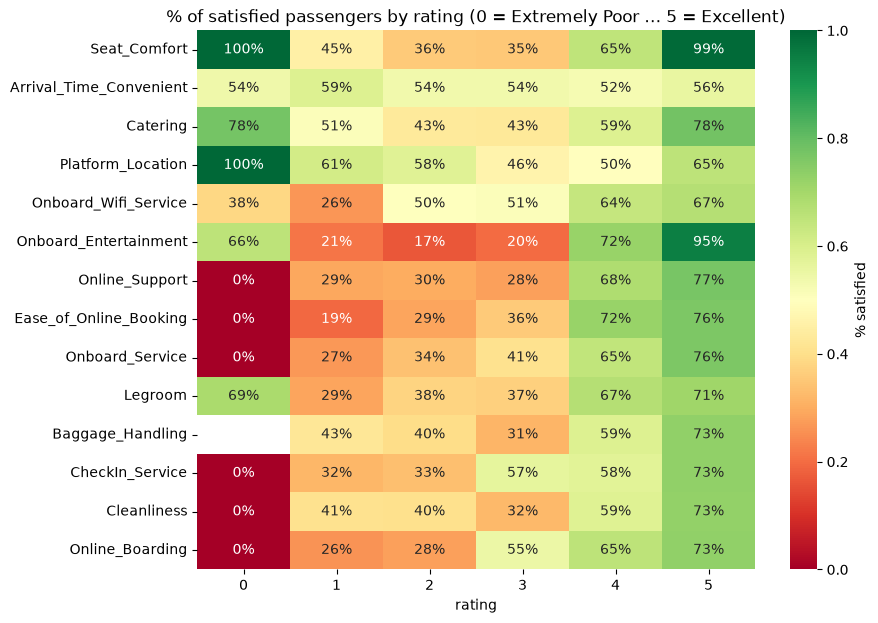

In [6]:
# Satisfaction rate by rating level, for every survey question
rates = pd.DataFrame({c: train_enc.groupby(c)[TARGET].mean() for c in survey_cols}).T
rates.columns = [f"{int(c)}" for c in rates.columns]
plt.figure(figsize=(9, 7))
sns.heatmap(rates, annot=True, fmt=".0%", cmap="RdYlGn", cbar_kws={"label": "% satisfied"})
plt.title("% of satisfied passengers by rating (0 = Extremely Poor … 5 = Excellent)"); plt.xlabel("rating")
plt.show()

In [7]:
# Data-quality check: how many passengers chose "Extremely Poor" (0), and how satisfied were they?
pd.DataFrame({"n_extremely_poor": (train_enc[survey_cols] == 0).sum(),
              "%_satisfied": [train_enc.loc[train_enc[c] == 0, TARGET].mean() for c in survey_cols]}).round(2).sort_values("n_extremely_poor", ascending=False).head(5)

,n_extremely_poor,%_satisfied
Arrival_Time_Convenient,4332,0.54
Catering,3910,0.78
Seat_Comfort,3463,1.00
Onboard_Entertainment,2144,0.66
Legroom,340,0.69


**Reading the heatmap**
- **Steepest rows = strongest drivers.** **Onboard entertainment** goes from ~21% satisfied at "Poor" to **95%** at "Excellent". **Ease of online booking** (19% → 76%) and **seat comfort** (45% → 99%) follow.
- **Flat rows:** **arrival time convenience** and **platform location** barely change satisfaction on their own.
- ⚠️ **Data-quality red flag:** 3,463 passengers rated seat comfort **"Extremely Poor"**, yet **100%** of them were satisfied (entertainment: 66%). That's not plausible, so the label is probably mis-coded in the survey export. The model will exploit it (it predicts the leaderboard well), but in a real project this is the **first question to take back to the data owner** before trusting any "seat comfort" conclusion.

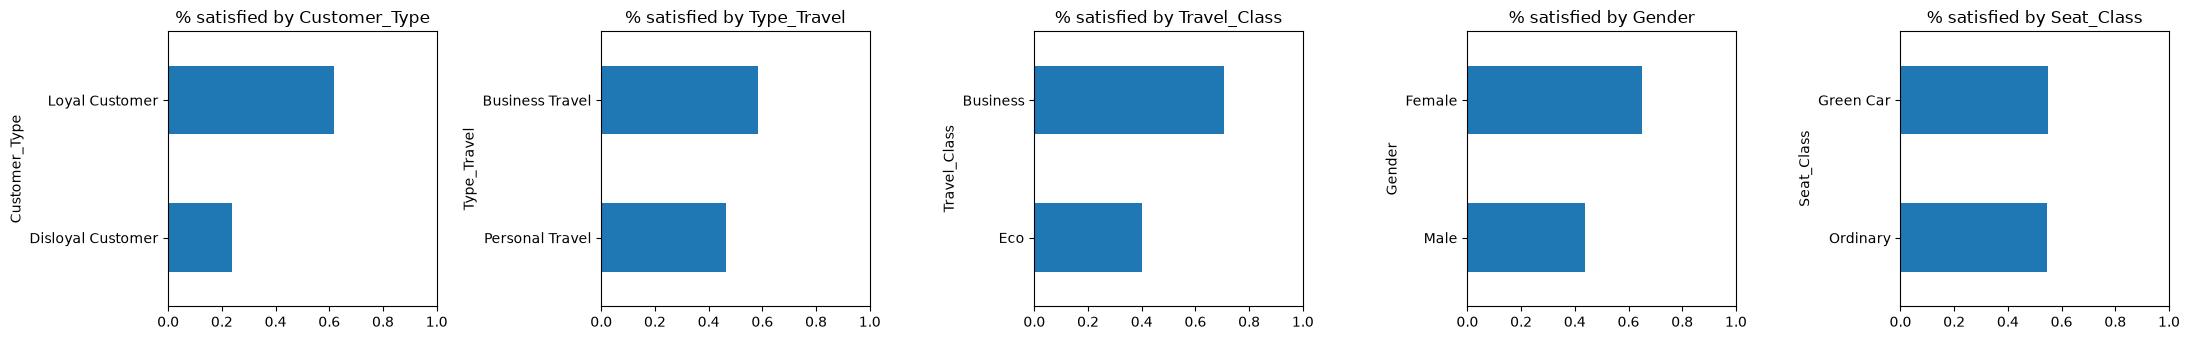

                       % satisfied  trips
Arrival_Delay_in_Mins                    
on time                      0.586  52915
1-15                         0.531  19721
16-60                        0.475  14827
>60                          0.439   6559


In [8]:
fig, ax = plt.subplots(1, 5, figsize=(22, 3.5))
for a, c in zip(ax, ["Customer_Type", "Type_Travel", "Travel_Class", "Gender", "Seat_Class"]):
    train.groupby(c)[TARGET].mean().sort_values().plot(kind="barh", ax=a, title=f"% satisfied by {c}", xlim=(0, 1))
plt.tight_layout(); plt.show()

delay_bins = pd.cut(train["Arrival_Delay_in_Mins"], [-1, 0, 15, 60, 2000], labels=["on time", "1-15", "16-60", ">60"])
print(train.groupby(delay_bins)[TARGET].agg(["mean", "size"]).rename(columns={"mean": "% satisfied", "size": "trips"}).round(3))

- **Loyal** customers are satisfied 62% of the time vs **24%** for disloyal ones; **Business class** 71% vs **Eco 40%**; business travel 58% vs personal 47%.
- **Women 65% vs men 44%**: a large gap worth investigating (which aspects do men rate lower?).
- **Seat class** (Green Car vs Ordinary) makes **no difference** (55% both).
- **Delays hurt, but less than the onboard experience**: 59% satisfied when on time vs **44%** with > 1 hour delay.

## 4. Preprocessing pipeline
One `ColumnTransformer`, fitted **only on training data** inside every model's pipeline (no leakage, the same transform for the submission):
- numeric + ordinal survey scores → **median imputation** (+ missing indicator, since not answering can be informative)
- nominal → **"Missing" category** + **one-hot**

In [9]:
X = train_enc.drop(columns=["ID", TARGET])
y = train_enc[TARGET]
X_test_final = test_enc.drop(columns=["ID"])

numeric_features = travel_numeric + survey_cols
preprocess = ColumnTransformer([
    ("num", SimpleImputer(strategy="median", add_indicator=True), numeric_features),
    ("cat", Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="Missing")),
                      ("onehot", OneHotEncoder(handle_unknown="ignore"))]), travel_nominal),
])

# Hold out 20% as an untouched test set; compare models on it
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
print(X_train.shape, X_val.shape)

(75503, 23) (18876, 23)


## 5. Model comparison

In [10]:
models = {
    "Logistic Regression": Pipeline([("prep", preprocess), ("scale", StandardScaler(with_mean=False)),
                                     ("clf", LogisticRegression(max_iter=2000))]),
    "Decision Tree":       Pipeline([("prep", preprocess), ("clf", DecisionTreeClassifier(max_depth=12, random_state=SEED))]),
    "Random Forest":       Pipeline([("prep", preprocess), ("clf", RandomForestClassifier(n_estimators=300, min_samples_leaf=2,
                                                                                         n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting (HistGB)": Pipeline([("prep", preprocess), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
    "Neural net (MLP)":    Pipeline([("prep", preprocess), ("scale", StandardScaler(with_mean=False)),
                                     ("clf", MLPClassifier(hidden_layer_sizes=(64, 32), early_stopping=True,
                                                           max_iter=200, random_state=SEED))]),
}

rows = []
for name, m in models.items():
    t0 = time.time(); m.fit(X_train, y_train)
    proba = m.predict_proba(X_val)[:, 1]; pred = (proba >= .5).astype(int)
    rows.append({"model": name, "train_acc": accuracy_score(y_train, m.predict(X_train)),
                 "val_acc": accuracy_score(y_val, pred), "val_f1": f1_score(y_val, pred),
                 "val_auc": roc_auc_score(y_val, proba), "fit_sec": time.time() - t0})
comparison = pd.DataFrame(rows).set_index("model").round(4).sort_values("val_acc", ascending=False)
comparison

,train_acc,val_acc,val_f1,val_auc,fit_sec
model,,,,,
Gradient Boosting (HistGB),0.9577,0.9498,0.9539,0.9919,1.9611
Random Forest,0.9908,0.9461,0.9507,0.9902,4.2238
Neural net (MLP),0.9543,0.9433,0.9474,0.9896,25.9693
Decision Tree,0.9530,0.9354,0.9407,0.9714,1.0680
Logistic Regression,0.8326,0.8346,0.8500,0.9072,2.0532


- **Tree ensembles win clearly** over the linear baseline (~0.95 vs ~0.83): satisfaction depends on **non-linear effects and interactions** (e.g. the U-shaped "Extremely Poor" pattern), which trees capture automatically.
- **Random Forest** overfits the most (train 0.99 vs val 0.95). **HistGB** has the best validation accuracy, a small train/val gap, and trains in ~2 s.
- The MLP is close, but slower and harder to explain, which confirms the deep learning topic's lesson for tabular data.

## 6. Tuning the best model
`HistGradientBoostingClassifier` = sklearn's LightGBM-style boosting: fast on 75k rows and handles missing values natively. Tuned with **RandomizedSearchCV** (random combinations instead of the full grid, much cheaper).

In [11]:
search = RandomizedSearchCV(
    Pipeline([("prep", preprocess), ("clf", HistGradientBoostingClassifier(random_state=SEED))]),
    param_distributions={
        "clf__learning_rate": [0.03, 0.05, 0.1, 0.2],
        "clf__max_iter": [300, 500, 800],
        "clf__max_leaf_nodes": [31, 63, 127],
        "clf__min_samples_leaf": [10, 20, 50],
        "clf__l2_regularization": [0, 0.1, 1.0],
    },
    n_iter=12, scoring="accuracy", cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
    n_jobs=-1, random_state=SEED,
).fit(X_train, y_train)
print("best params:", {k.replace("clf__", ""): v for k, v in search.best_params_.items()})
print(f"best CV accuracy: {search.best_score_:.4f}")
best = search.best_estimator_

best params: {'min_samples_leaf': 20, 'max_leaf_nodes': 63, 'max_iter': 800, 'learning_rate': 0.1, 'l2_regularization': 0.1}
best CV accuracy: 0.9549


## 7. Evaluation on the held-out set

Tuned HistGB: accuracy 0.9542 | F1 0.9580 | ROC-AUC 0.9933


Train accuracy 0.9781  (gap = overfitting check)
               precision    recall  f1-score   support

Not satisfied      0.945     0.955     0.950      8557
    Satisfied      0.962     0.954     0.958     10319

     accuracy                          0.954     18876
    macro avg      0.954     0.954     0.954     18876
 weighted avg      0.954     0.954     0.954     18876



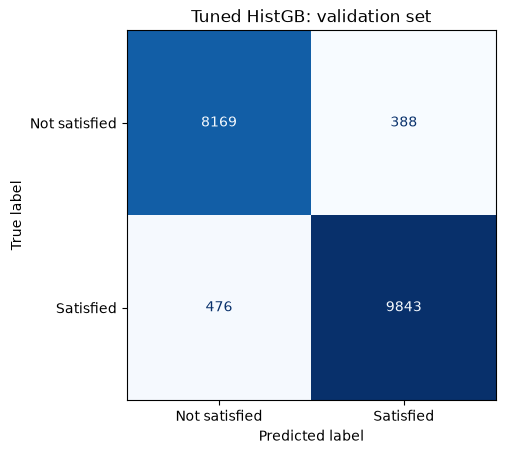

In [12]:
proba = best.predict_proba(X_val)[:, 1]; pred = (proba >= .5).astype(int)
print(f"Tuned HistGB: accuracy {accuracy_score(y_val, pred):.4f} | F1 {f1_score(y_val, pred):.4f} | ROC-AUC {roc_auc_score(y_val, proba):.4f}")
print(f"Train accuracy {accuracy_score(y_train, best.predict(X_train)):.4f}  (gap = overfitting check)")
print(classification_report(y_val, pred, target_names=["Not satisfied", "Satisfied"], digits=3))
ConfusionMatrixDisplay.from_predictions(y_val, pred, display_labels=["Not satisfied", "Satisfied"], cmap="Blues", colorbar=False)
plt.title("Tuned HistGB: validation set"); plt.show()

## 8. Explainability: what drives satisfaction?
**Permutation importance**: shuffle one column and measure how much accuracy drops. Model-agnostic, computed on **validation** data, on the **original** columns (before one-hot).

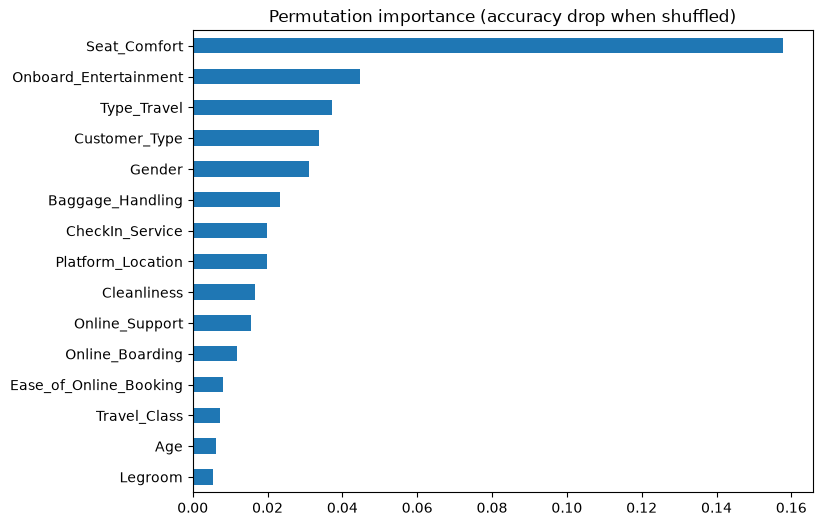

Seat_Comfort             0.1578
Onboard_Entertainment    0.0446
Type_Travel              0.0372
Customer_Type            0.0338
Gender                   0.0311
Baggage_Handling         0.0234
CheckIn_Service          0.0200
Platform_Location        0.0198
dtype: float64

In [13]:
sample = X_val.sample(8000, random_state=SEED)
perm = permutation_importance(best, sample, y_val.loc[sample.index], scoring="accuracy",
                              n_repeats=5, random_state=SEED, n_jobs=-1)
importance = pd.Series(perm.importances_mean, index=sample.columns).sort_values()
importance.tail(15).plot(kind="barh", figsize=(8, 6), title="Permutation importance (accuracy drop when shuffled)")
plt.show()
importance.sort_values(ascending=False).head(8).round(4)

**Reading it:** **seat comfort** dominates (part of it is the suspicious "Extremely Poor" label, see EDA), then **onboard entertainment**, **travel type**, **customer type** and **gender**.
The digital-journey questions (online booking, support, boarding) look strong in the EDA but rank lower here because they're **correlated with each other**: shuffling one barely hurts while the others carry the same signal. Permutation importance **splits shared information**.

### Business recommendations
1. **Seat comfort and onboard entertainment** are the biggest levers: entertainment alone takes satisfaction from ~21% to 95% across its scale. Validate the seat-comfort labels first (see the data-quality flag).
2. **Fix the digital journey as one package** (online booking, online support, online boarding). Each one moves satisfaction from ~20–30% to ~75%.
3. **Target the at-risk segments:** disloyal customers (24% satisfied), Eco class (40%), personal travel (47%). They're the retention-offer audience.
4. **Investigate the gender gap** (65% vs 44%) with a follow-up survey before acting on it.
5. **Low priority:** arrival time convenience and platform location (flat satisfaction curves), and seat class (no difference). Delays matter but are secondary, so communication and compensation for > 60-minute delays are cheaper than infrastructure.

## 9. Final model & submission
Refit the tuned pipeline on **all** labeled data, predict the test set, and save the whole pipeline (preprocessing + model) with `joblib`: one file that takes raw rows and returns predictions, ready to serve behind an API (the MLOps step).

In [14]:
final_model = search.best_estimator_.fit(X, y)
submission = pd.DataFrame({"ID": test["ID"], TARGET: final_model.predict(X_test_final)})
submission.to_csv("submission.csv", index=False)
joblib.dump(final_model, "model.joblib")          # git-ignored: rebuild it by running the notebook
print(submission.shape, f"| predicted satisfied: {submission[TARGET].mean():.1%}")
submission.head()

(35602, 2) | predicted satisfied: 54.1%


,ID,Overall_Experience
0,99900001,1
1,99900002,1
2,99900003,1
3,99900004,0
4,99900005,1


In [15]:
# Using the saved model on new raw data (exactly what an API endpoint would do)
loaded = joblib.load("model.joblib")
new_trip = test_enc.drop(columns=["ID"]).iloc[[0]]
print("prediction:", loaded.predict(new_trip)[0], "| probability satisfied:", loaded.predict_proba(new_trip)[0, 1].round(3))

prediction: 1 | probability satisfied: 0.995
